# Voz, ruido y filtros pasa banda
### Reto de Procesos Estocásticos · 2026 SEM II
**Mateo Oñate y William Garzón** · Yachay Tech University

Este cuaderno desarrolla los puntos 1–4 del examen con la grabación **libri1** adjunta.
Se comparan un Butterworth analógico discretizado (A) y un Chebyshev I digital (B), ambos de orden cuatro.

**Cómo trabajar juntos en Colab:** suban este `.ipynb` a Google Drive, ábranlo con Colaboratory y compartan el mismo archivo con permiso de edición. Una persona ejecuta las celdas en orden y la otra verifica argumentos y resultados. Usen comentarios para discutir cambios. Eviten ejecutar simultáneamente sobre el mismo entorno. El archivo se ejecuta también fuera de Colab.

**Ruta de lectura:** 0 preparación → 1 evidencia y banda → 2 diseños → 3 modelos y estabilidad → 4 verificaciones → 5 ruido y métricas → 6 escucha y exportación → 7 defensa.

Los resultados numéricos se regeneran al ejecutar todo. **Queda por hacer por los dos integrantes:** escuchar los modos, registrar sus observaciones reales y confirmar el reparto de contribuciones. Las medidas objetivas no certifican inteligibilidad. No se atribuyen escuchas ni trabajo personal que no se hayan confirmado.

## 0 · Entorno, parámetros y fuente
La instalación añade solamente dependencias ausentes. Se registra la versión realmente utilizada; no se fuerza una actualización de las bibliotecas de Colab. No se necesita cuenta de dataset ni API.

In [1]:
import importlib.util, subprocess, sys
required = {'numpy':'numpy>=1.26,<3', 'scipy':'scipy>=1.11,<2',
            'matplotlib':'matplotlib>=3.7,<4', 'pandas':'pandas>=2,<4',
            'soundfile':'soundfile>=0.12,<0.15', 'ipywidgets':'ipywidgets>=8,<9'}
missing=[spec for name,spec in required.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
import os, json, hashlib, urllib.request, platform, shutil, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import signal, optimize
import matplotlib
import matplotlib.pyplot as plt
import soundfile as sf
import ipywidgets as widgets
from IPython.display import Audio, display, Markdown, FileLink
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':170,'font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.grid':True,'grid.alpha':0.20})
COLORS={'A':'#176b87','B':'#b45522'}
ROOT=Path.cwd()
RESULT=ROOT/'results'
FIG=RESULT/'figures'; TABLE=RESULT/'tables'; AUD=RESULT/'audio'
for p in [FIG,TABLE,AUD]: p.mkdir(parents=True,exist_ok=True)
VERSIONS={'python':platform.python_version(), **{m:importlib.import_module(m).__version__
           for m in ['numpy','scipy','matplotlib','pandas','soundfile','ipywidgets']}}
print(json.dumps(VERSIONS,indent=2))

{
  "python": "3.10.5",
  "numpy": "1.26.4",
  "scipy": "1.11.4",
  "matplotlib": "3.9.2",
  "pandas": "2.2.3",
  "soundfile": "0.14.0",
  "ipywidgets": "8.1.9"
}


In [2]:
# Parámetros únicos: cambiar aquí y volver a ejecutar TODO.
NAMES=['Mateo Oñate','William Garzón']
SOURCE_URL='https://librosa.org/data/audio/5703-47212-0000.ogg'
META_URL='https://librosa.org/data/audio/5703-47212-0000.txt'
EXPECTED_SHA='a284612b46af0535f7e1873758c4387bb8369f6dbbe192ffdec1f171108f98dd'
SEEDS=[117,229,353,487,619]
fL,fH=60.0,5000.0
INTERIOR=(120.0,3500.0)
STOP_LOW=(0.0,20.0)
STOP_HIGH_START=8500.0
SPEC={'variation_db':1.0,'attenuation_db':18.0,'delay_ms':6.0,'edge_tolerance_pct':1.0}
CANDIDATES=[(60.0,5000.0),(150.0,3500.0)]
RP_DB=1.0
NPERSEG=4096; NOVERLAP=2048
STFT_N=1024; STFT_HOP=256
ACTIVE=[(0.35,2.70),(3.45,4.40),(10.40,11.40)]
BACKGROUND=[(0.02,0.25),(4.55,4.68),(9.85,10.15)]
source_path=AUD/'5703-47212-0000.ogg'
if not source_path.exists():
    try:
        with urllib.request.urlopen(SOURCE_URL,timeout=60) as response:
            source_path.write_bytes(response.read())
    except Exception as exc:
        print('Descarga no disponible. Suban el OGG adjunto para continuar.',exc)
        try:
            from google.colab import files
            uploaded=files.upload()
            name=next(k for k in uploaded if k.lower().endswith('.ogg'))
            source_path.write_bytes(uploaded[name])
        except ImportError:
            raise RuntimeError(f'Copie el archivo original en {source_path}') from exc
sha=hashlib.sha256(source_path.read_bytes()).hexdigest()
assert sha==EXPECTED_SHA, 'El archivo no coincide con la grabación verificada; revise la fuente.'
metadata=('Ashiel Mystery - A Detective Story, chapter 2, narrated by Garth Comira\n'
          'LibriSpeech SLR12: https://www.openslr.org/12/\n'
          'CC-BY 4.0: https://creativecommons.org/licenses/by/4.0/')
try:
    metadata=urllib.request.urlopen(META_URL,timeout=20).read().decode('utf-8').strip()
except Exception:
    print('Metadatos web no disponibles. Se conserva la atribución verificada.')
(RESULT/'source_metadata.txt').write_text(metadata,encoding='utf-8')
raw,fs=sf.read(source_path,dtype='float64',always_2d=True)
channels=raw.shape[1]
r=raw.mean(axis=1) # El archivo verificado ya es mono. No se remuestrea.
duration=len(r)/fs
STOP_HIGH=(STOP_HIGH_START,fs/2)
assert 0<fL<fH<fs/2
print(metadata)
print(f'fs={fs} Hz; duración={duration:.6f} s; canales={channels}; muestras={len(r)}')
print('Clip completo: [0, duración). Sin remuestreo, normalización ni eliminación de DC del registro.')
print('SHA-256:',sha)

Ashiel Mystery - A Detective Story, chapter 2, narrated by Garth Comira
From the LibriSpeech SLR12 collection: https://www.openslr.org/12/
CC-BY 4.0 https://creativecommons.org/licenses/by/4.0/
fs=22050 Hz; duración=14.840000 s; canales=1; muestras=327222
Clip completo: [0, duración). Sin remuestreo, normalización ni eliminación de DC del registro.
SHA-256: a284612b46af0535f7e1873758c4387bb8369f6dbbe192ffdec1f171108f98dd


## 1 · Evidencia para elegir la banda (punto 1.1)
Se usa el clip completo para conservar frases y pausas. Las ventanas **activas** se eligieron por la forma de onda y estructura armónica; las ventanas de **baja actividad** son candidatas a fondo, con posible respiración/reverberación. No contienen necesariamente ruido puro.

Welch del clip: ventana Hann periódica, 4096 muestras, solapamiento 2048, `detrend='constant'`, densidad unilateral en amplitud digital²/Hz. Resolución $f_s/4096$. Para activos/fondo se calcula cada intervalo por separado y se promedian sus PSD ponderando su duración, sin concatenar discontinuidades. Si el intervalo es corto se acorta la ventana, con menor resolución efectiva, sobre la misma rejilla FFT de 4096 puntos. STFT: Hann, 1024 muestras, salto 256, sin relleno ni extensión. Magnitud en dB respecto a amplitud digital 1. Estos niveles no son dB SPL.

La banda ancha 60–5000 Hz busca conservar la fundamental grave y episodios de contenido alto compatibles con consonantes. La candidata 150–3500 Hz sirve para medir el coste de una selección más estrecha. La energía por sí sola favorece vocales fuertes y puede ocultar consonantes de baja energía: las dos bandas se escuchan en la sección 6 antes de confirmar la decisión.

Welch: Δf= 5.38330078125 Hz. STFT: ventana= 46.439909297052154 ms, salto= 11.609977324263038 ms.
Activos: [(0.35, 2.7), (3.45, 4.4), (10.4, 11.4)] ; baja actividad: [(0.02, 0.25), (4.55, 4.68), (9.85, 10.15)]


,banda_hz,fL_hz,fH_hz,energia_pct
0,60-5000,60.0,5000.0,98.885961
1,150-3500,150.0,3500.0,59.897691


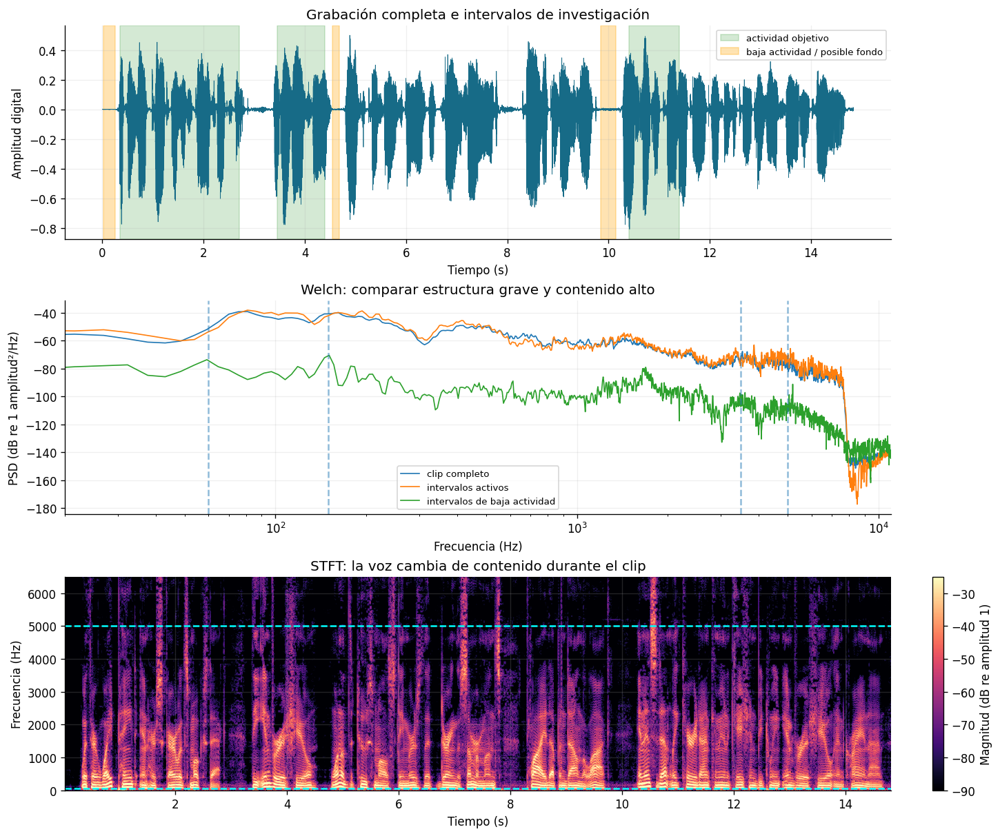

In [3]:
integrate=np.trapezoid if hasattr(np,'trapezoid') else np.trapz
def rms(x): return float(np.sqrt(np.mean(np.asarray(x)**2)))
def psd(x):
    return signal.welch(x,fs=fs,window='hann',nperseg=min(NPERSEG,len(x)),
                        noverlap=min(NOVERLAP,len(x)//2),detrend='constant',scaling='density')
def bandpower(f,P,band):
    lo,hi=band
    grid=np.r_[lo,f[(f>lo)&(f<hi)],hi]
    return float(integrate(np.interp(grid,f,P),grid))
def db(x): return 20*np.log10(np.maximum(np.abs(x),1e-15))
def savefig(fig,name):
    fig.savefig(FIG/f'{name}.png',bbox_inches='tight')
    plt.show(); plt.close(fig)
fP,Pr=psd(r)
candidate_rows=[]
for lo,hi in CANDIDATES:
    p=bandpower(fP,Pr,(lo,hi))
    candidate_rows.append({'banda_hz':f'{lo:g}-{hi:g}','fL_hz':lo,'fH_hz':hi,
                           'energia_pct':100*p/bandpower(fP,Pr,(0,fs/2))})
candidates=pd.DataFrame(candidate_rows)
display(candidates)
candidates.to_csv(TABLE/'candidate_bands.csv',index=False)
def interval_psd(intervals):
    spectra=[];weights=[]
    for a,b in intervals:
        z=r[int(a*fs):int(b*fs)];nseg=min(NPERSEG,len(z))
        ff,pp=signal.welch(z,fs,window='hann',nperseg=nseg,noverlap=nseg//2,
                           nfft=NPERSEG,detrend='constant',scaling='density')
        spectra.append(pp);weights.append(len(z))
    return ff,np.average(spectra,axis=0,weights=weights)
fAct,pAct=interval_psd(ACTIVE); fBg,pBg=interval_psd(BACKGROUND)
fig,ax=plt.subplots(3,1,figsize=(12,10),constrained_layout=True)
t=np.arange(len(r))/fs
ax[0].plot(t,r,lw=.45,color=COLORS['A'])
for i,(a,b) in enumerate(ACTIVE): ax[0].axvspan(a,b,color='green',alpha=.17,label='actividad objetivo' if i==0 else None)
for i,(a,b) in enumerate(BACKGROUND): ax[0].axvspan(a,b,color='orange',alpha=.3,label='baja actividad / posible fondo' if i==0 else None)
ax[0].set(xlabel='Tiempo (s)',ylabel='Amplitud digital',title='Grabación completa e intervalos de investigación');ax[0].legend(fontsize=8,loc='upper right')
for f,p,label in [(fP,Pr,'clip completo'),(fAct,pAct,'intervalos activos'),(fBg,pBg,'intervalos de baja actividad')]:
    ax[1].semilogx(f[1:],10*np.log10(np.maximum(p[1:],1e-20)),label=label,lw=1)
for lo,hi in CANDIDATES:
    ax[1].axvline(lo,ls='--',alpha=.5);ax[1].axvline(hi,ls='--',alpha=.5)
ax[1].set(xlim=(20,fs/2),xlabel='Frecuencia (Hz)',ylabel='PSD (dB re 1 amplitud²/Hz)',title='Welch: comparar estructura grave y contenido alto');ax[1].legend(fontsize=8)
fst,tst,Z=signal.stft(r,fs,window='hann',nperseg=STFT_N,noverlap=STFT_N-STFT_HOP,boundary=None,padded=False)
im=ax[2].pcolormesh(tst,fst,db(Z),shading='auto',vmin=-90,vmax=-25,cmap='magma')
ax[2].axhline(fH,color='cyan',ls='--');ax[2].axhline(fL,color='cyan',ls='--')
ax[2].set(ylim=(0,6500),xlabel='Tiempo (s)',ylabel='Frecuencia (Hz)',title='STFT: la voz cambia de contenido durante el clip')
fig.colorbar(im,ax=ax[2],label='Magnitud (dB re amplitud 1)')
savefig(fig,'01_signal_evidence')
print('Welch: Δf=',fs/NPERSEG,'Hz. STFT: ventana=',1000*STFT_N/fs,'ms, salto=',1000*STFT_HOP/fs,'ms.')
print('Activos:',ACTIVE,'; baja actividad:',BACKGROUND)

### Especificaciones antes de comparar diseños
Se desean bordes de media potencia $-10\log_{10}2=-3.0103$ dB en 60 y 5000 Hz, tolerancia 1%. La banda interior 120–3500 Hz evita exigir ganancia plana en la transición. Las bandas de rechazo son [0,20] y [8500,11025] Hz. Se desea variación pico a pico ≤1 dB, rechazo mínimo ≥18 dB y máximo retardo de grupo interior ≤6 ms. Son objetivos de orden bajo, no una promesa de eliminación completa del ruido.

La comparación de energía es un argumento medido para la banda, no una frontera universal del habla. El sonido puede resultar menos grave o brillante tras filtrar. Completen sus observaciones auditivas al final.

## 2 · Diseños competidores y derivaciones (puntos 1.2–1.3)
### A · Butterworth continuo → pasa banda → Tustin
El prototipo normalizado de orden $N=2$ es
$$H_{LP}(p)=\frac{1}{p^2+\sqrt2p+1}.$$
Con $\Omega_L=2f_s\tan(\pi f_L/f_s)$, $\Omega_H=2f_s\tan(\pi f_H/f_s)$, $B=\Omega_H-\Omega_L$ y $\Omega_0=\sqrt{\Omega_L\Omega_H}$, usamos
$$p=\frac{s^2+\Omega_0^2}{Bs},\qquad
H_c(s)=\frac{B^2s^2}{s^4+\sqrt2Bs^3+(B^2+2\Omega_0^2)s^2+\sqrt2B\Omega_0^2s+\Omega_0^4}.$$
La sustitución duplica el orden: **cuatro**. En $s=j\Omega$, los bordes llevan $p=\pm j$, por lo que son de media potencia.
$$H_A(z)=H_c\!\left(2f_s\frac{1-z^{-1}}{1+z^{-1}}\right).$$
Para $z=e^{j\omega}$, $s=j2f_s\tan(\omega/2)$. La relación no es lineal: se predeforman **ambos** bordes, no solo la frecuencia central. `bilinear_zpk` no agrega esa corrección por nosotros.

### B · Chebyshev I digital de orden final cuatro
`cheby1(2, rp=1, btype='bandpass', fs=fs)` proporciona una familia distinta con dos SOS y rizado de 1 dB. Sus frecuencias críticas son de **−1 dB**, no de −3 dB. Para compartir exactamente los bordes de media potencia de A se ajustan esas frecuencias críticas.

Como $|H_{LP}(jq)|^2=[1+\epsilon^2 T_2(q)^2]^{-1}$, $\epsilon=\sqrt{10^{1/10}-1}$, $T_2(q)=2q^2-1$, en media potencia $q_3=\sqrt{(1+1/\epsilon)/2}$. El ancho del prototipo pasa banda debe ser $B_p=B/q_3$. Se calculan sus bordes críticos predeformados con
$$\Omega_{p,L/H}=\frac{\sqrt{B_p^2+4\Omega_0^2}\mp B_p}{2},\qquad
f_{p,L/H}=\frac{f_s}{\pi}\arctan\frac{\Omega_{p,L/H}}{2f_s}.$$
Estas frecuencias se entregan al diseñador **digital**. Esto conserva el rizado y permite comparar igual banda objetivo y orden. No se está presentando un Butterworth digital idéntico como competidor. No se eligió FIR, por lo que el límite de 65 taps y la convención −6 dB de `firwin` no intervienen.

In [4]:
OmegaL,OmegaH=2*fs*np.tan(np.pi*np.array([fL,fH])/fs)
BW=OmegaH-OmegaL; Omega0=np.sqrt(OmegaL*OmegaH)
zp,pp,kp=signal.buttap(2)
zc,pc,kc=signal.lp2bp_zpk(zp,pp,kp,wo=Omega0,bw=BW)
bc,ac=signal.zpk2tf(zc,pc,kc)
za,pa,ka=signal.bilinear_zpk(zc,pc,kc,fs=fs)
sosA=signal.zpk2sos(za,pa,ka)
eps=np.sqrt(10**(RP_DB/10)-1)
q3=np.sqrt((1+1/eps)/2)
Bp=BW/q3
critical_analog=np.array([(np.sqrt(Bp**2+4*Omega0**2)-Bp)/2,
                          (np.sqrt(Bp**2+4*Omega0**2)+Bp)/2])
critical_B=fs/np.pi*np.arctan(critical_analog/(2*fs))
sosB=signal.cheby1(2,RP_DB,critical_B,btype='bandpass',fs=fs,output='sos')
FILTERS={'A':sosA,'B':sosB}
BA={k:signal.sos2tf(s) for k,s in FILTERS.items()}
for k,(b,a) in BA.items(): BA[k]=(b/a[0],a/a[0])
# Diagnóstico que deliberadamente omite prewarping.
znp,pnp,knp=signal.lp2bp_zpk(zp,pp,kp,wo=2*np.pi*np.sqrt(fL*fH),bw=2*np.pi*(fH-fL))
znp,pnp,knp=signal.bilinear_zpk(znp,pnp,knp,fs=fs)
sosNP=signal.zpk2sos(znp,pnp,knp)
direct_check=signal.butter(2,[fL,fH],btype='bandpass',fs=fs,output='sos')
fcheck=np.linspace(0,fs/2,20001)
check_error=float(np.max(np.abs(signal.sosfreqz(sosA,worN=fcheck,fs=fs)[1]-signal.sosfreqz(direct_check,worN=fcheck,fs=fs)[1])))
print('ΩL, ΩH (rad/s):',OmegaL,OmegaH,'; B:',BW,'; Ω0:',Omega0)
print('Frecuencias críticas B de -1 dB (Hz):',critical_B)
print('Verificación A contra butter digital idéntico, error de respuesta:',check_error)
assert check_error<1e-10

ΩL, ΩH (rad/s): 377.00030191781985 38088.0335202201 ; B: 37711.033218302284 ; Ω0: 3789.3535248877242
Frecuencias críticas B de -1 dB (Hz): [  72.71437908 4345.75502887]
Verificación A contra butter digital idéntico, error de respuesta: 6.616966482467247e-14


## 3 · Modelos, recurrencia, estabilidad y causalidad (puntos 2.1–2.2)
Con condiciones iniciales nulas, la EDO de A es
$$y^{(4)}+\sqrt2 B y^{(3)}+(B^2+2\Omega_0^2)y''+\sqrt2B\Omega_0^2y'+\Omega_0^4 y=B^2 x''.$$
Los vectores analógicos se imprimen en potencias **descendentes** de $s$. Para ambos digitales se usa $a_0=1$ y orden creciente de retardos:
$$H(z)=\frac{\sum_{k=0}^{4}b_kz^{-k}}{1+\sum_{k=1}^{4}a_kz^{-k}},\qquad
y[n]=\sum_{k=0}^{4}b_kx[n-k]-\sum_{k=1}^{4}a_ky[n-k].$$
El código siguiente genera las ecuaciones numéricas sin transcribir coeficientes a mano. La implementación explícita de la recurrencia se usa solo para verificar un bloque corto; todos los experimentos emplean `sosfilt` causal de una pasada, estados iniciales cero. No se usa `filtfilt`.

Hc: numerador descendente s: [1.422122026392e+09 0.000000000000e+00 0.000000000000e+00] 
Hc: denominador descendente s: [1.000000000000e+00 5.333145462843e+04 1.450840426665e+09 7.657970305844e+11 2.061866285623e+14]
EDO numérica: y^(4) + (53331.4546284) y^(3) + (1450840426.67) y'' + (765797030584) y' + (2.06186628562e+14) y = (1422122026.39) x''

Filtro A b= [ 0.246680399457  0.             -0.493360798915  0.              0.246680399457] 
a= [ 1.             -2.159208471568  1.52085976491  -0.539408642743  0.178051588975] 
SOS= [[ 0.246680399457  0.493360798915  0.246680399457  1.             -0.183382473331  0.18240738148 ]
 [ 1.             -2.              1.              1.             -1.975825998237  0.976120525001]]
y[n] = +0.246680399457 x[n-0] +0 x[n-1] -0.493360798915 x[n-2] +0 x[n-3] +0.246680399457 x[n-4] +2.15920847157 y[n-1] -1.52085976491 y[n-2] +0.539408642743 y[n-3] -0.178051588975 y[n-4]

Filtro B b= [ 0.207533727158  0.             -0.415067454316  0.              

,filtro,max_modulo_polo,ROC_causal
0,A,0.987988,|z| > 0.987988119868
1,B,0.989853,|z| > 0.989852854594


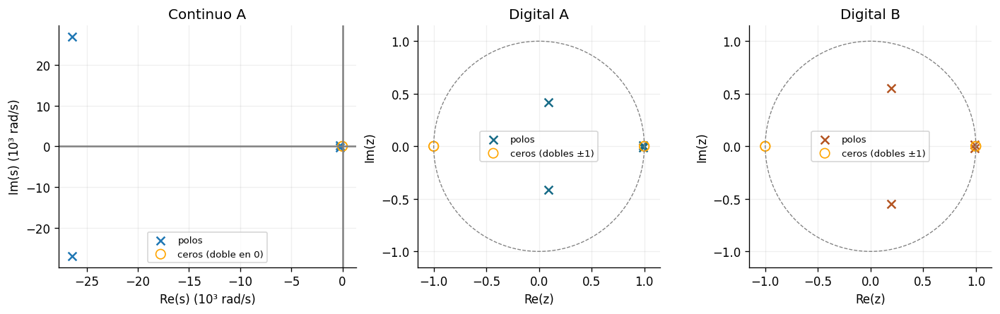

In [5]:
np.set_printoptions(precision=12,suppress=False,linewidth=140)
print('Hc: numerador descendente s:',bc,'\nHc: denominador descendente s:',ac)
print(f'EDO numérica: y^(4) + ({ac[1]:.12g}) y^(3) + ({ac[2]:.12g}) y\'\' + ({ac[3]:.12g}) y\' + ({ac[4]:.12g}) y = ({bc[0]:.12g}) x\'\'')
for k,sos in FILTERS.items():
    b,a=BA[k]
    print('\nFiltro',k,'b=',b,'\na=',a,'\nSOS=',sos)
    print('y[n] = '+' '.join(f'{v:+.12g} x[n-{i}]' for i,v in enumerate(b))
          +' '+' '.join(f'{-v:+.12g} y[n-{i}]' for i,v in enumerate(a[1:],1)))
def explicit_recursion(x,b,a):
    x=np.asarray(x,dtype=float); y=np.zeros_like(x)
    for n in range(len(x)):
        y[n]=sum(b[k]*x[n-k] for k in range(len(b)) if n>=k)
        y[n]-=sum(a[k]*y[n-k] for k in range(1,len(a)) if n>=k)
    return y
test_rng=np.random.default_rng(2026)
test_x=test_rng.standard_normal(512)
b,a=BA['A']
rec_error=float(np.max(np.abs(explicit_recursion(test_x,b,a)-signal.sosfilt(sosA,test_x))))
print('\nMáximo error absoluto recurrencia / sosfilt:',rec_error)
assert rec_error<1e-9
digital_poles={k:signal.sos2zpk(s)[1] for k,s in FILTERS.items()}
stability=[]
for k,p in digital_poles.items():
    assert np.max(np.abs(p))<1
    stability.append({'filtro':k,'max_modulo_polo':float(np.max(np.abs(p))),
                      'ROC_causal':f'|z| > {np.max(np.abs(p)):.12g}'})
assert np.max(pc.real)<0
print('Polos analógicos (rad/s):',pc)
print('Polo(s) más próximo(s) al eje imaginario:',pc[np.isclose(pc.real,max(pc.real))])
print(f'ROC analógica causal: Re(s) > {max(pc.real):.12g} rad/s')
display(pd.DataFrame(stability))
for k,p in digital_poles.items(): print('Polos digitales',k,p)
fig,ax=plt.subplots(1,3,figsize=(12,3.6),constrained_layout=True)
ax[0].scatter(pc.real/1000,pc.imag/1000,marker='x',s=50,label='polos')
ax[0].scatter(zc.real/1000,zc.imag/1000,facecolors='none',edgecolors='orange',s=65,label='ceros (doble en 0)')
ax[0].axvline(0,color='gray');ax[0].axhline(0,color='gray');ax[0].set(xlabel='Re(s) (10³ rad/s)',ylabel='Im(s) (10³ rad/s)',title='Continuo A');ax[0].legend(fontsize=8)
theta=np.linspace(0,2*np.pi,500)
for axis,(k,sos) in zip(ax[1:],FILTERS.items()):
    z,p,_=signal.sos2zpk(sos)
    axis.plot(np.cos(theta),np.sin(theta),color='gray',ls='--',lw=.8)
    axis.scatter(p.real,p.imag,marker='x',c=COLORS[k],s=50,label='polos')
    axis.scatter(z.real,z.imag,facecolors='none',edgecolors='orange',s=65,label='ceros (dobles ±1)')
    axis.set(xlim=(-1.15,1.15),ylim=(-1.15,1.15),xlabel='Re(z)',ylabel='Im(z)',title='Digital '+k,aspect='equal');axis.legend(fontsize=8)
savefig(fig,'02_poles')

Un sistema racional causal es BIBO estable si su ROC incluye el eje imaginario (continuo) o el círculo unidad (discreto). Los valores anteriores verifican ambas condiciones. El continuo tiene dos ceros en $s=0$ y dos en infinito, que Tustin lleva respectivamente a $z=1$ y $z=-1$. Para $s=\sigma+j\Omega$,
$$|z|^2=\frac{(1+\sigma/(2f_s))^2+(\Omega/(2f_s))^2}{(1-\sigma/(2f_s))^2+(\Omega/(2f_s))^2}<1\quad(\sigma<0).$$
Así, Tustin preserva la estabilidad del semiplano izquierdo. La causalidad se impone con ecuaciones que dependen de entradas presentes/pasadas y salidas pasadas, nunca futuras.

## 4 · Verificaciones de frecuencia y tiempo (punto 2.3)
### 4.1 · Bordes medidos, fase, retardo y cumplimiento
Se buscan cruces **reales** con $|H|=1/\sqrt2$ mediante Brent. La variación es máximo menos mínimo de ganancia en la banda interior; el rechazo mínimo es el negativo de la mayor ganancia en cada banda de rechazo. El retardo máximo se evalúa solo en el interior, en milisegundos. No se interpreta el retardo en DC/Nyquist, donde hay ceros y la fase no está definida.

Bordes analíticos sin prewarp: [  59.998538509447 4344.497339744619]


,filtro,borde,deseado_hz,medido_hz,error_hz,error_pct
0,A,inferior,60.0,60.000000,2.753353e-11,4.588922e-11
1,A,superior,5000.0,5000.000000,0.000000e+00,0.000000e+00
2,B,inferior,60.0,60.000000,-1.606537e-11,-2.677562e-11
3,B,superior,5000.0,5000.000000,9.094947e-13,1.818989e-14
4,sin_prewarp,inferior,60.0,59.998539,-1.461491e-03,-2.435818e-03
5,sin_prewarp,superior,5000.0,4344.497340,-6.555027e+02,-1.311005e+01


,filtro,orden,SOS,variacion_db,ganancia_min_db,ganancia_max_db,rechazo_bajo_db,rechazo_alto_db,retardo_max_ms,retardo_min_ms,variacion_cumple,rechazo_bajo_cumple,rechazo_alto_cumple,retardo_cumple
0,A,4,2,0.602053,-0.602053,5.785965e-14,19.290358,19.734051,1.152696,0.047252,True,True,True,True
1,B,4,2,1.000000,-1.000000,-1.565598e-09,22.510469,22.973406,1.366617,0.043355,True,True,True,True


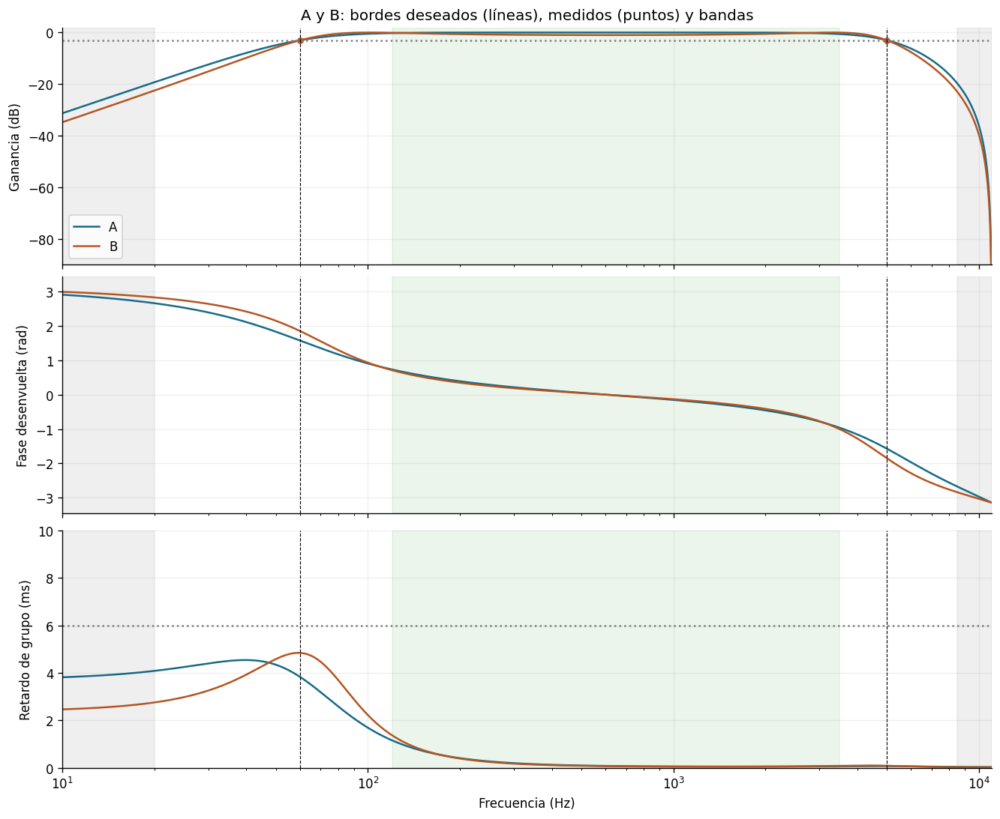

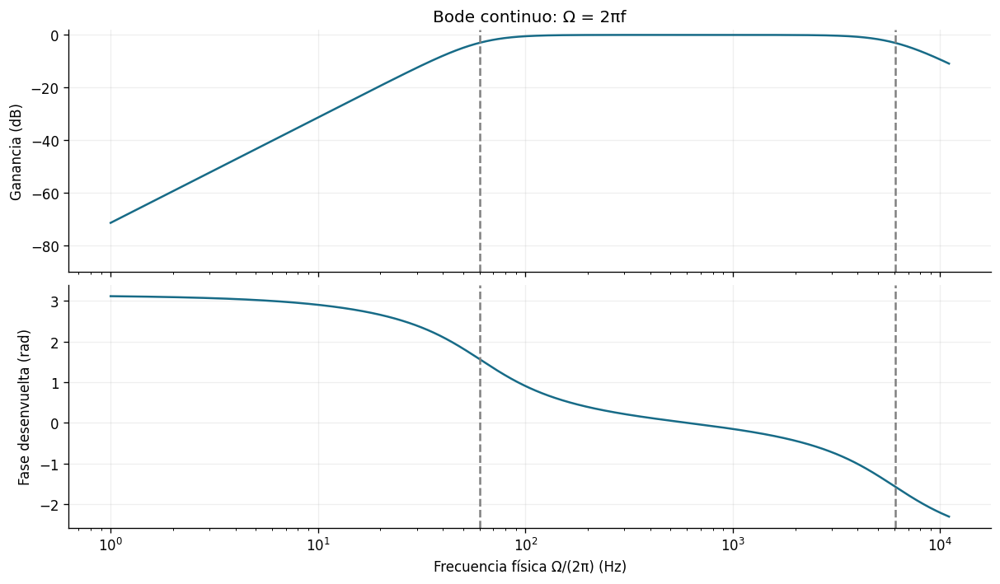

In [6]:
TARGET_DB=-10*np.log10(2)
def response(sos,f): return signal.sosfreqz(sos,worN=np.atleast_1d(f),fs=fs)[1]
def measure_edges(sos):
    g=lambda f: float(db(response(sos,f))[0]-TARGET_DB)
    return [optimize.brentq(g,max(.001,fL*.05),np.sqrt(fL*fH)),
            optimize.brentq(g,np.sqrt(fL*fH),fs/2-.001)]
edge_rows=[]
for label,sos in [('A',sosA),('B',sosB),('sin_prewarp',sosNP)]:
    for side,desired,measured in zip(['inferior','superior'],[fL,fH],measure_edges(sos)):
        edge_rows.append({'filtro':label,'borde':side,'deseado_hz':desired,'medido_hz':measured,
                          'error_hz':measured-desired,'error_pct':100*(measured-desired)/desired})
edges=pd.DataFrame(edge_rows);display(edges);edges.to_csv(TABLE/'edges.csv',index=False)
print('Bordes analíticos sin prewarp:',fs/np.pi*np.arctan(np.pi*np.array([fL,fH])/fs))
freq=np.geomspace(1,fs/2-.01,30000)
metrics=[]
for k,sos in FILTERS.items():
    fi=np.linspace(*INTERIOR,16000)
    gains=db(response(sos,fi))
    b,a=BA[k]
    gd=signal.group_delay((b,a),w=2*np.pi*fi/fs)[1]/fs*1000
    reject=[]
    for band in [STOP_LOW,STOP_HIGH]: reject.append(float(-np.max(db(response(sos,np.linspace(*band,12000))))))
    metrics.append({'filtro':k,'orden':4,'SOS':len(sos),'variacion_db':float(np.ptp(gains)),
                    'ganancia_min_db':float(np.min(gains)),'ganancia_max_db':float(np.max(gains)),
                    'rechazo_bajo_db':reject[0],'rechazo_alto_db':reject[1],
                    'retardo_max_ms':float(max(gd)),'retardo_min_ms':float(min(gd)),
                    'variacion_cumple':bool(np.ptp(gains)<=SPEC['variation_db']+1e-8),
                    'rechazo_bajo_cumple':bool(reject[0]>=SPEC['attenuation_db']),
                    'rechazo_alto_cumple':bool(reject[1]>=SPEC['attenuation_db']),
                    'retardo_cumple':bool(max(gd)<=SPEC['delay_ms'])})
freq_metrics=pd.DataFrame(metrics);display(freq_metrics);freq_metrics.to_csv(TABLE/'frequency_metrics.csv',index=False)
fig,ax=plt.subplots(3,1,figsize=(11,9),sharex=True,constrained_layout=True)
for k,sos in FILTERS.items():
    h=response(sos,freq);b,a=BA[k]
    gd=signal.group_delay((b,a),w=2*np.pi*freq/fs)[1]/fs*1000
    ax[0].semilogx(freq,db(h),label=k,color=COLORS[k])
    ax[1].semilogx(freq,np.unwrap(np.angle(h)),color=COLORS[k])
    ax[2].semilogx(freq,gd,color=COLORS[k])
    for edge in measure_edges(sos):ax[0].plot(edge,TARGET_DB,'o',color=COLORS[k],ms=4)
for axis in ax:
    axis.axvspan(*INTERIOR,color='green',alpha=.08)
    axis.axvspan(max(1,STOP_LOW[0]),STOP_LOW[1],color='gray',alpha=.12)
    axis.axvspan(*STOP_HIGH,color='gray',alpha=.12)
    for edge in [fL,fH]:axis.axvline(edge,color='black',ls='--',lw=.7)
ax[0].axhline(TARGET_DB,color='gray',ls=':');ax[0].set(ylim=(-90,2),ylabel='Ganancia (dB)',title='A y B: bordes deseados (líneas), medidos (puntos) y bandas');ax[0].legend()
ax[1].set(ylabel='Fase desenvuelta (rad)')
ax[2].axhline(SPEC['delay_ms'],ls=':',color='gray');ax[2].set(xlabel='Frecuencia (Hz)',ylabel='Retardo de grupo (ms)',ylim=(0,10),xlim=(10,fs/2))
savefig(fig,'03_digital_response')
fig,ax=plt.subplots(2,1,figsize=(10,5.8),sharex=True,constrained_layout=True)
fa=np.geomspace(1,fs/2,5000)
ha=signal.freqs(bc,ac,worN=2*np.pi*fa)[1]
ax[0].semilogx(fa,db(ha),color=COLORS['A']);ax[0].set(ylabel='Ganancia (dB)',ylim=(-90,2),title='Bode continuo: Ω = 2πf')
ax[1].semilogx(fa,np.unwrap(np.angle(ha)),color=COLORS['A']);ax[1].set(xlabel='Frecuencia física Ω/(2π) (Hz)',ylabel='Fase desenvuelta (rad)')
for axis in ax:
    for omega in [OmegaL,OmegaH]: axis.axvline(omega/(2*np.pi),ls='--',color='gray')
savefig(fig,'04_analog_bode')

### 4.2 · Hz físicos y eje correctamente deformado
En Hz físicos se compara $H_c(j2\pi f)$ con $H_A(e^{j2\pi f/f_s})$. No se espera identidad: los bordes analógicos son $\Omega_{L,H}/(2\pi)$ Hz físicos, no $f_{L,H}$. En el segundo panel se evalúa $H_c(j\Omega)$ con $\Omega=2f_s\tan(\pi f/f_s)$ y ambos se dibujan sobre ese mismo eje. Nyquist se excluye porque $\Omega\to\infty$.

Error complejo máximo sobre eje deformado: 7.7762747510907e-13


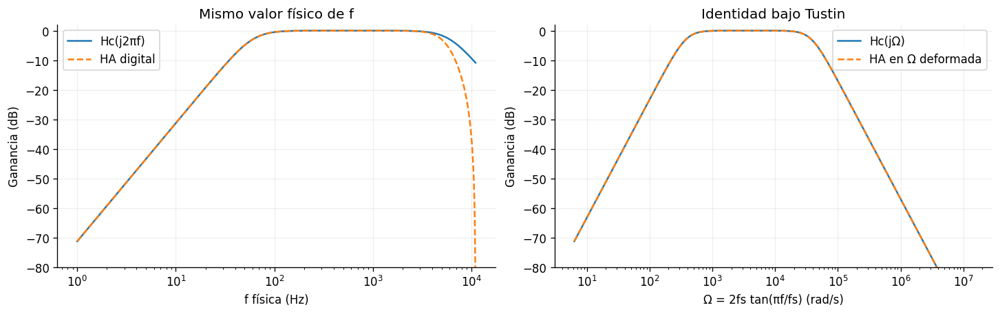

In [7]:
fw=np.geomspace(1,.499*fs,12000)
Omega_w=2*fs*np.tan(np.pi*fw/fs)
hA=response(sosA,fw)
hPhysical=signal.freqs(bc,ac,worN=2*np.pi*fw)[1]
hWarped=signal.freqs(bc,ac,worN=Omega_w)[1]
warp_error=float(np.max(abs(hA-hWarped)))
fig,ax=plt.subplots(1,2,figsize=(12,3.7),constrained_layout=True)
ax[0].semilogx(fw,db(hPhysical),label='Hc(j2πf)');ax[0].semilogx(fw,db(hA),ls='--',label='HA digital');ax[0].set(xlabel='f física (Hz)',ylabel='Ganancia (dB)',ylim=(-80,2),title='Mismo valor físico de f');ax[0].legend()
ax[1].semilogx(Omega_w,db(hWarped),label='Hc(jΩ)');ax[1].semilogx(Omega_w,db(hA),ls='--',label='HA en Ω deformada');ax[1].set(xlabel='Ω = 2fs tan(πf/fs) (rad/s)',ylabel='Ganancia (dB)',ylim=(-80,2),title='Identidad bajo Tustin');ax[1].legend()
savefig(fig,'05_warping')
print('Error complejo máximo sobre eje deformado:',warp_error);assert warp_error<1e-10

### 4.3 · Impulso verdadero y escalón
`signal.impulse` aplica la distribución impulso al sistema continuo. Una muestra de altura uno no sería ese impulso: sus unidades y área difieren. Los impulsos discretos tienen $\delta[0]=1$. En un pasa banda ideal en DC, $H_c(0)=H_A(1)=H_B(1)=0$, por lo que el escalón tiende a cero tras el transitorio. No deben compararse las alturas del impulso continuo (1/s) y discreto como si tuvieran idénticas unidades.

Cola escalón continuo: 0.0
Cola escalón A -2.3314683517128287e-15
Cola escalón B -1.454392162258955e-14


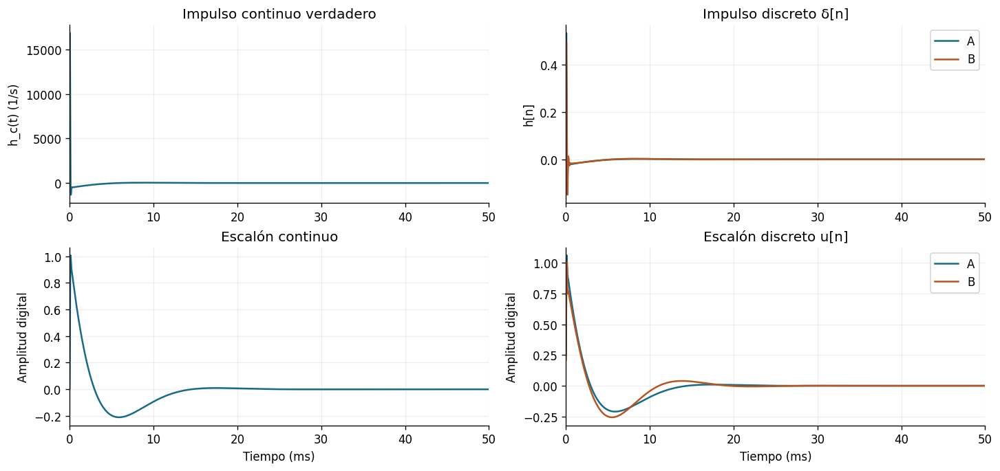

In [8]:
tc=np.linspace(0,.15,12001)
_,hc=signal.impulse((bc,ac),T=tc)
_,sc=signal.step((bc,ac),T=tc)
nresp=int(.15*fs);td=np.arange(nresp)/fs
delta=np.r_[1.,np.zeros(nresp-1)]
fig,ax=plt.subplots(2,2,figsize=(12,5.6),constrained_layout=True)
ax[0,0].plot(tc*1000,hc,color=COLORS['A']);ax[0,0].set(title='Impulso continuo verdadero',ylabel='h_c(t) (1/s)')
ax[1,0].plot(tc*1000,sc,color=COLORS['A']);ax[1,0].set(title='Escalón continuo',ylabel='Amplitud digital',xlabel='Tiempo (ms)')
for k,sos in FILTERS.items():
    ax[0,1].plot(td*1000,signal.sosfilt(sos,delta),label=k,color=COLORS[k])
    ax[1,1].plot(td*1000,signal.sosfilt(sos,np.ones(nresp)),label=k,color=COLORS[k])
ax[0,1].set(title='Impulso discreto δ[n]',ylabel='h[n]');ax[0,1].legend()
ax[1,1].set(title='Escalón discreto u[n]',xlabel='Tiempo (ms)',ylabel='Amplitud digital');ax[1,1].legend()
for axis in ax.flat:axis.set_xlim(0,50)
savefig(fig,'06_impulse_step')
print('Cola escalón continuo:',sc[-1])
for k,sos in FILTERS.items():print('Cola escalón',k,signal.sosfilt(sos,np.ones(nresp))[-1])

### 4.4 · Tres tonos y convergencia de simulación analógica
Los tonos están en 20 Hz (rechazo bajo), 1000 Hz (interior) y 8500 Hz (rechazo alto), con amplitud 0,2 cada uno. Se estiman las amplitudes con ajuste **conjunto** de senos/cosenos y constante tras 0,3 s. Así no se mezcla la potencia de los tres tonos.

`lsim(..., interp=True)` simula exactamente el sistema para una entrada interpolada linealmente entre muestras. Primero se usa $\Delta t=1/(8f_s)$ y luego $\Delta t/2$. Esta comprobación evalúa la representación de la entrada y el espaciado de salida, no finge cambiar una tolerancia interna de integración. Se comparan también las salidas en tiempos comunes. Los digitales usan el $f_s$ nativo.

dt inicial: 5.668934240362812e-06 s; dt refinado: 2.834467120181406e-06 s; max diferencia en tiempos comunes: 0.0006519842174649015
Cambio máximo de ganancias al refinar: 0.002564777863075518


,sistema,tono_hz,predicho,medido,error_abs
0,Hc,20.0,0.108512,0.108512,1.145484e-09
1,Hc,1000.0,0.999937,0.999910,2.643450e-05
2,Hc,8500.0,0.449815,0.448957,8.581827e-04
3,A,20.0,0.108513,0.108513,2.618461e-13
4,A,1000.0,0.999933,0.999933,3.108624e-15
5,A,8500.0,0.103109,0.103109,4.135581e-15
6,B,20.0,0.074899,0.074899,1.570410e-13
7,B,1000.0,0.897496,0.897496,2.442491e-15
8,B,8500.0,0.071012,0.071012,2.720046e-15


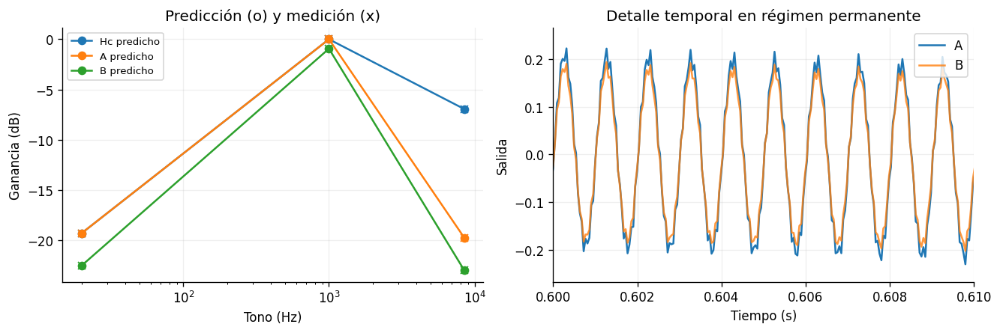

In [9]:
TONES=np.array([20.,1000.,8500.]); TONE_AMP=.2
def three_tone(t): return TONE_AMP*np.sin(2*np.pi*t[:,None]*TONES).sum(axis=1)
def fit_amplitudes(t,y,discard=.3):
    keep=t>=discard; tt=t[keep]
    X=np.column_stack([np.ones(len(tt)),*[v for f in TONES for v in (np.sin(2*np.pi*f*tt),np.cos(2*np.pi*f*tt))]])
    c=np.linalg.lstsq(X,y[keep],rcond=None)[0]
    return np.hypot(c[1::2],c[2::2])/TONE_AMP
dt=1/(8*fs);tcoarse=np.arange(round(1.2/dt))*dt
tfine=np.arange(2*len(tcoarse))*dt/2
_,yc,_=signal.lsim((bc,ac),U=three_tone(tcoarse),T=tcoarse,interp=True)
_,yf,_=signal.lsim((bc,ac),U=three_tone(tfine),T=tfine,interp=True)
gcoarse=fit_amplitudes(tcoarse,yc);gfine=fit_amplitudes(tfine,yf)
convergence=float(np.max(abs(yf[::2]-yc)))
rows=[]
predAnalog=abs(signal.freqs(bc,ac,worN=2*np.pi*TONES)[1])
for f,p,m in zip(TONES,predAnalog,gfine):rows.append({'sistema':'Hc','tono_hz':f,'predicho':p,'medido':m,'error_abs':abs(p-m)})
ttone=np.arange(round(1.2*fs))/fs;xtone=three_tone(ttone)
digital_tone={}
for k,sos in FILTERS.items():
    yy=signal.sosfilt(sos,xtone);digital_tone[k]=yy
    pred=abs(response(sos,TONES));meas=fit_amplitudes(ttone,yy)
    for f,p,m in zip(TONES,pred,meas):rows.append({'sistema':k,'tono_hz':f,'predicho':p,'medido':m,'error_abs':abs(p-m)})
tone_table=pd.DataFrame(rows);display(tone_table);tone_table.to_csv(TABLE/'three_tone.csv',index=False)
print('dt inicial:',dt,'s; dt refinado:',dt/2,'s; max diferencia en tiempos comunes:',convergence)
print('Cambio máximo de ganancias al refinar:',float(max(abs(gfine-gcoarse))))
fig,ax=plt.subplots(1,2,figsize=(11,3.6),constrained_layout=True)
for i,k in enumerate(['Hc','A','B']):
    z=tone_table[tone_table.sistema==k]
    ax[0].plot(z.tono_hz,20*np.log10(z.predicho),'o-',label=f'{k} predicho')
    ax[0].plot(z.tono_hz,20*np.log10(z.medido),'x',color=ax[0].lines[-1].get_color())
ax[0].set(xscale='log',xlabel='Tono (Hz)',ylabel='Ganancia (dB)',title='Predicción (o) y medición (x)');ax[0].legend(fontsize=8)
ax[1].plot(ttone,digital_tone['A'],label='A');ax[1].plot(ttone,digital_tone['B'],label='B',alpha=.8)
ax[1].set(xlim=(.6,.61),xlabel='Tiempo (s)',ylabel='Salida',title='Detalle temporal en régimen permanente');ax[1].legend()
savefig(fig,'07_three_tone')

## 5 · Corrupción controlada y métricas honestas (punto 3)
Se conserva $r[n]$, grabación **con su fondo inherente**. Se construye
$$x=r(1+\beta m)+\alpha v,\qquad \alpha=\mathrm{RMS}(r)10^{-\mathrm{SNR}_{add}/20}.$$
Cada realización se descentra y normaliza a RMS=1 **antes** de escalar. Se usan cinco semillas y subflujos independientes para $v$, ruido coloreado y $m$. El ruido blanco gaussiano es la referencia común. El coloreado es ruido blanco pasado por un Butterworth causal de orden dos, corte 300 Hz: PSD proporcional a $|H_{LP}(f)|^2$, un modelo de retumbo grave. $m$ se obtiene con otro Butterworth de orden dos y corte 5 Hz: fluctuación lenta de ganancia. Se generan 2 s de precalentamiento para estos generadores y se descartan antes de normalizar.

En frecuencia, $\mathcal{F}\{rm\}=R*M$: aparecen bandas laterales alrededor de las componentes de la voz. El ruido multiplicativo se solapa con la voz y un filtro LTI no lo separa necesariamente. El SNR combinado se mide; el parámetro 5 dB solo especifica la parte aditiva.

### Definiciones y ventana común
Para $e=x-r$, con cero inicial y la **misma** ventana temporal $I$:
$$\mathrm{SNR}^{ref}_{in}=10\log_{10}\frac{\sum_I r^2}{\sum_I e^2},\quad
\mathrm{SNR}^{ref}_{out}=10\log_{10}\frac{\sum_I (Hr)^2}{\sum_I(He)^2},\quad\Delta=out-in.$$
Estas razones miden rechazo de corrupción añadida respecto al registro filtrado. No son el SNR verdadero de voz limpia.

La fidelidad respecto a la grabación se expresa como RMSE/correlación entre $Hx$ y $r$, cruda y compensada por **un único lag por filtro**, obtenido solo con $r$. Si el lag $\ell$ es positivo se compara $y[n+\ell]$ con $r[n]$. Un lag negativo también es posible por la fase de un pasa banda y la periodicidad local de la voz. Esta compensación no elimina distorsión de fase dependiente de frecuencia.

Retención en la banda seleccionada = $\int_{f_L}^{f_H}\!P_{Hr}/\int_{f_L}^{f_H}\!P_r$. Esta banda difiere del interior 120–3500 Hz usado en las especificaciones. Atenuación del error en cada rechazo = $10\log_{10}(\int P_e/\int P_{He})$. Se integra PSD lineal con interpolación en límites exactos, nunca dB. Para baseline $e=0$, SNR=∞ y Δ/atenuaciones no aplican. La retención depende del filtro y no de la semilla.

Lag fijo (muestras): {'A': 0, 'B': 0} ; lag (ms): {'A': 0.0, 'B': 0.0}
Exclusión inicial=0.2s; margen por alineación=0 muestras; intervalo I=[0.200000,14.840000) s; N efectivo=322812


,filter,snr_in_db,snr_out_db,delta_snr_db,rmse_aligned,corr_aligned,rmse_raw,corr_raw,retention_pct,atten_low_db,atten_high_db
0,A,inf,inf,NaN,0.072046,0.788929,0.072046,0.788929,93.425578,NaN,NaN
1,B,inf,inf,NaN,0.076262,0.757425,0.076262,0.757425,87.628290,NaN,NaN


snr_in_db           ... atten_high_db         
                             mean      std  ...          mean      std
case             filter                     ...                       
colored_5dB      A        5.05738  0.00565  ...      22.33848  0.01009
                 B        5.05738  0.00565  ...      25.64306  0.01052
combined_5dB_030 A        3.92578  0.05363  ...      26.93979  0.04248
                 B        3.92578  0.05363  ...      30.28103  0.04308
mult_010         A       19.87774  0.26787  ...      30.79528  0.59208
                 B       19.87774  0.26787  ...      34.16191  0.60001
mult_030         A       10.33531  0.26787  ...      30.79528  0.59208
                 B       10.33531  0.26787  ...      34.16191  0.60001
white_20dB       A       20.05907  0.00054  ...      26.93979  0.04248
                 B       20.05907  0.00054  ...      30.28103  0.04308
white_5dB        A        5.05907  0.00054  ...      26.93979  0.04248
                 B        5.05907  0.00054  ...      30.28103  0.04308

[12 rows x 20 columns]

,caso,filtro,snr_in_db,snr_out_db,delta_snr_db,rmse_aligned,corr_aligned
0,white_20dB,A,20.0591 ± 0.0005,23.1671 ± 0.0116,3.1081 ± 0.0113,0.0724 ± 0.0000,0.7870 ± 0.0001
1,white_20dB,B,20.0591 ± 0.0005,23.1409 ± 0.0113,3.0818 ± 0.0110,0.0766 ± 0.0000,0.7555 ± 0.0001
2,white_5dB,A,5.0591 ± 0.0005,8.1671 ± 0.0116,3.1081 ± 0.0113,0.0836 ± 0.0001,0.7346 ± 0.0004
3,white_5dB,B,5.0591 ± 0.0005,8.1409 ± 0.0113,3.0818 ± 0.0110,0.0867 ± 0.0001,0.7049 ± 0.0005
4,mult_010,A,19.8777 ± 0.2679,19.8760 ± 0.2869,-0.0017 ± 0.0228,0.0728 ± 0.0001,0.7848 ± 0.0008
5,mult_010,B,19.8777 ± 0.2679,19.8840 ± 0.2818,0.0063 ± 0.0149,0.0769 ± 0.0001,0.7534 ± 0.0012
6,mult_030,A,10.3353 ± 0.2679,10.3336 ± 0.2869,-0.0017 ± 0.0228,0.0789 ± 0.0005,0.7538 ± 0.0035
7,mult_030,B,10.3353 ± 0.2679,10.3416 ± 0.2818,0.0063 ± 0.0149,0.0824 ± 0.0005,0.7235 ± 0.0044
8,combined_5dB_030,A,3.9258 ± 0.0536,6.0978 ± 0.0903,2.1720 ± 0.0371,0.0896 ± 0.0004,0.7045 ± 0.0046
9,combined_5dB_030,B,3.9258 ± 0.0536,6.0846 ± 0.0876,2.1589 ± 0.0340,0.0922 ± 0.0004,0.6759 ± 0.0054


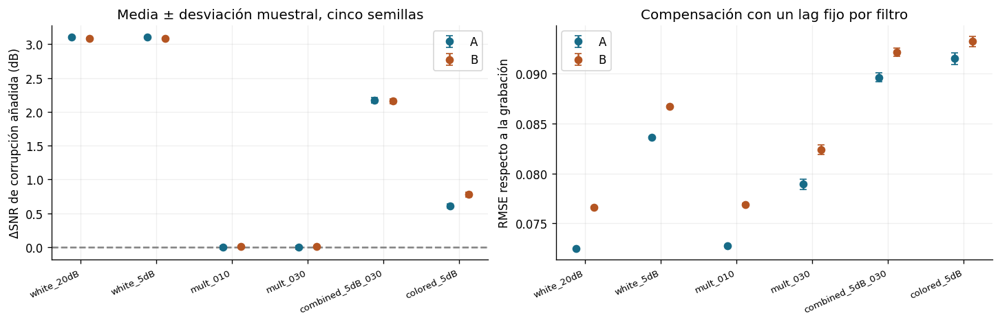

In [10]:
CASES={
 'baseline':(None,0.,'none'), 'white_20dB':(20.,0.,'white'),
 'white_5dB':(5.,0.,'white'), 'mult_010':(None,.10,'none'),
 'mult_030':(None,.30,'none'), 'combined_5dB_030':(5.,.30,'white'),
 'colored_5dB':(5.,0.,'colored')}
def unit_noise(x):
    x=np.asarray(x,dtype=float);x=x-x.mean()
    return x/rms(x)
def noise_components(seed):
    streams=[np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(3)]
    v=unit_noise(streams[0].standard_normal(len(r)))
    pad=2*fs
    col=signal.sosfilt(signal.butter(2,300,fs=fs,output='sos'),streams[1].standard_normal(len(r)+pad))[pad:]
    m=signal.sosfilt(signal.butter(2,5,fs=fs,output='sos'),streams[2].standard_normal(len(r)+pad))[pad:]
    return v,unit_noise(col),unit_noise(m)
NOISE={seed:noise_components(seed) for seed in SEEDS}
def make_case(case,seed):
    snr,beta,kind=CASES[case]
    if case=='baseline':return r.copy()
    white,colored,m=NOISE[seed]
    v=colored if kind=='colored' else white
    alpha=0. if snr is None else rms(r)*10**(-snr/20)
    return r*(1+beta*m)+alpha*v
Hr={k:signal.sosfilt(sos,r) for k,sos in FILTERS.items()}
exclude_s=.2; start=int(np.ceil(exclude_s*fs))
search=int(.02*fs)
LAGS={}
for k,y in Hr.items():
    cc=signal.correlate(y[start:],r[start:],mode='full',method='fft')
    lagvec=signal.correlation_lags(len(y)-start,len(r)-start,mode='full')
    mask=abs(lagvec)<=search
    LAGS[k]=int(lagvec[mask][np.argmax(cc[mask])])
guard=max(abs(v) for v in LAGS.values())
I=np.arange(start+guard,len(r)-guard)
print('Lag fijo (muestras):',LAGS,'; lag (ms):',{k:1000*v/fs for k,v in LAGS.items()})
print(f'Exclusión inicial={exclude_s}s; margen por alineación={guard} muestras; intervalo I=[{I[0]/fs:.6f},{(I[-1]+1)/fs:.6f}) s; N efectivo={len(I)}')
def ratio_db(a,b):
    if b==0:return np.inf if a>0 else np.nan
    if a==0:return -np.inf
    return 10*np.log10(a/b)
def correlation(a,b):
    return float(np.corrcoef(a,b)[0,1]) if np.std(a)>0 and np.std(b)>0 else np.nan
fr_eval,pr_eval=psd(r[I])
RETENTION={k:bandpower(*psd(y[I]),(fL,fH))/bandpower(fr_eval,pr_eval,(fL,fH)) for k,y in Hr.items()}
rows=[]
for case in CASES:
    for seed in ([SEEDS[0]] if case=='baseline' else SEEDS):
        x=make_case(case,seed);e=x-r
        for k,sos in FILTERS.items():
            he=signal.sosfilt(sos,e);hx=signal.sosfilt(sos,x)
            assert np.max(abs(hx-(Hr[k]+he)))<1e-10
            sin=ratio_db(np.sum(r[I]**2),np.sum(e[I]**2))
            sout=ratio_db(np.sum(Hr[k][I]**2),np.sum(he[I]**2))
            atts=[]
            for band in [STOP_LOW,STOP_HIGH]:
                pe=bandpower(*psd(e[I]),band);phe=bandpower(*psd(he[I]),band)
                atts.append(ratio_db(pe,phe) if pe>0 and phe>0 else np.nan)
            rows.append({'case':case,'seed':int(seed),'filter':k,'snr_in_db':sin,'snr_out_db':sout,
                         'delta_snr_db':sout-sin if np.isfinite(sin) else np.nan,
                         'snr_in_full_db':ratio_db(np.sum(r*r),np.sum(e*e)),
                         'rmse_aligned':rms(hx[I+LAGS[k]]-r[I]),'corr_aligned':correlation(hx[I+LAGS[k]],r[I]),
                         'rmse_raw':rms(hx[I]-r[I]),'corr_raw':correlation(hx[I],r[I]),
                         'retention_pct':100*RETENTION[k],'atten_low_db':atts[0],'atten_high_db':atts[1],
                         'lag_samples':LAGS[k],'n_eval':len(I),'peak_input':float(max(abs(x)))})
trials=pd.DataFrame(rows)
trials.to_csv(TABLE/'all_trials.csv',index=False)
measure_cols=['snr_in_db','snr_out_db','delta_snr_db','rmse_aligned','corr_aligned',
              'rmse_raw','corr_raw','retention_pct','atten_low_db','atten_high_db']
baseline=trials[trials.case=='baseline'].copy();display(baseline[['filter',*measure_cols]])
noisy=trials[trials.case!='baseline']
grouped=noisy.groupby(['case','filter'])[measure_cols].agg(['mean','std'])
display(grouped.round(5))
grouped.to_csv(TABLE/'noise_mean_std.csv')
formatted=[]
aggregates=[]
for (case,k),z in noisy.groupby(['case','filter'],sort=False):
    row={'case':case,'filter':k,'n_seeds':len(z)};fmt={'caso':case,'filtro':k}
    for col in measure_cols:
        mean=float(z[col].mean());std=float(z[col].std(ddof=1))
        row[col+'_mean']=mean;row[col+'_std']=std
        fmt[col]=f'{mean:.4f} ± {std:.4f}'
    aggregates.append(row);formatted.append(fmt)
aggregate_table=pd.DataFrame(aggregates)
pd.DataFrame(formatted).to_csv(TABLE/'noise_readable.csv',index=False)
display(pd.DataFrame(formatted)[['caso','filtro','snr_in_db','snr_out_db','delta_snr_db','rmse_aligned','corr_aligned']])
fig,ax=plt.subplots(1,2,figsize=(12,3.8),constrained_layout=True)
case_order=list(CASES)[1:];pos=np.arange(len(case_order))
for k,shift in [('A',-.12),('B',.12)]:
    vals=aggregate_table[aggregate_table['filter']==k].set_index('case').loc[case_order]
    ax[0].errorbar(pos+shift,vals.delta_snr_db_mean,yerr=vals.delta_snr_db_std,fmt='o',capsize=3,label=k,color=COLORS[k])
    ax[1].errorbar(pos+shift,vals.rmse_aligned_mean,yerr=vals.rmse_aligned_std,fmt='o',capsize=3,label=k,color=COLORS[k])
for axis in ax:axis.set_xticks(pos,case_order,rotation=25,ha='right',fontsize=8);axis.legend()
ax[0].axhline(0,color='gray',ls='--');ax[0].set(ylabel='ΔSNR de corrupción añadida (dB)',title='Media ± desviación muestral, cinco semillas')
ax[1].set(ylabel='RMSE respecto a la grabación',title='Compensación con un lag fijo por filtro')
savefig(fig,'08_noise_metrics')

### Evidencia espectral de ruido y salidas
La comparación de PSD comprueba la forma de los generadores. Los espectrogramas usan idénticos parámetros y escala. La señal combinada de demostración corresponde a la primera semilla, sin elegir un caso especialmente favorable. Las métricas se calculan antes de cualquier factor de reproducción.

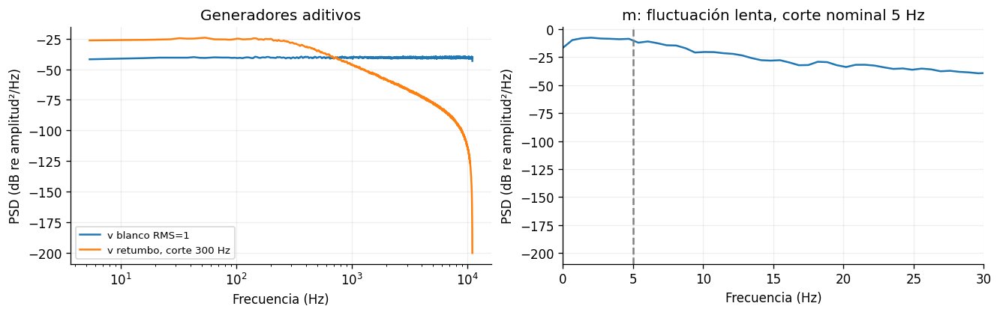

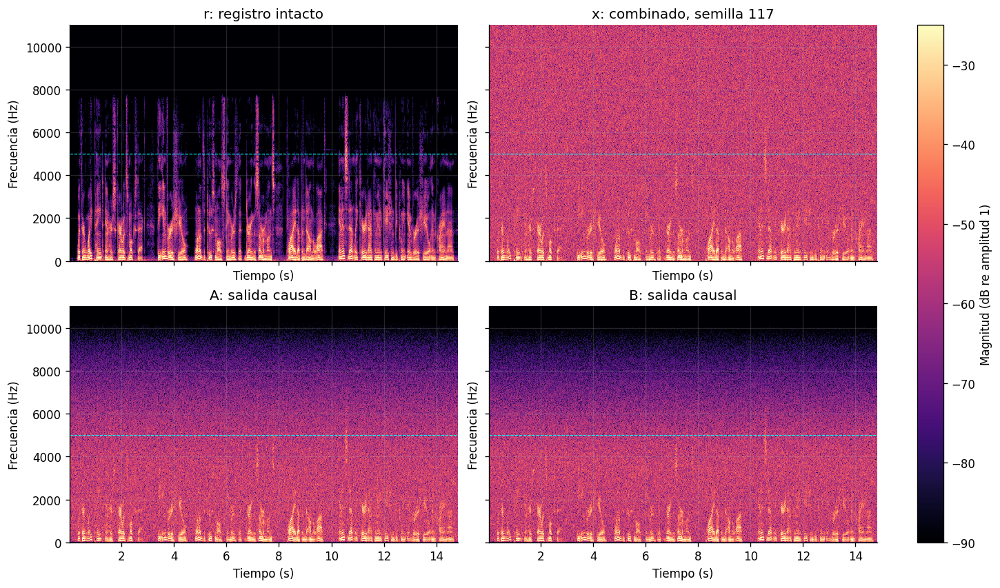

In [11]:
v,col,m=NOISE[SEEDS[0]]
fig,ax=plt.subplots(1,2,figsize=(11,3.4),constrained_layout=True)
for z,label in [(v,'v blanco RMS=1'),(col,'v retumbo, corte 300 Hz')]:
    f,p=psd(z);ax[0].semilogx(f[1:],10*np.log10(np.maximum(p[1:],1e-20)),label=label)
ax[0].set(xlabel='Frecuencia (Hz)',ylabel='PSD (dB re amplitud²/Hz)',title='Generadores aditivos');ax[0].legend(fontsize=8)
fm,pm=signal.welch(m,fs,nperseg=32768,noverlap=16384)
ax[1].plot(fm,10*np.log10(np.maximum(pm,1e-20)));ax[1].axvline(5,ls='--',color='gray');ax[1].set(xlim=(0,30),xlabel='Frecuencia (Hz)',ylabel='PSD (dB re amplitud²/Hz)',title='m: fluctuación lenta, corte nominal 5 Hz')
savefig(fig,'09_noise_psd')
demo=make_case('combined_5dB_030',SEEDS[0])
signals=[('r: registro intacto',r),('x: combinado, semilla 117',demo),('A: salida causal',signal.sosfilt(sosA,demo)),('B: salida causal',signal.sosfilt(sosB,demo))]
fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True,sharey=True,constrained_layout=True)
for axis,(label,z) in zip(axes.flat,signals):
    ff,tt,zz=signal.stft(z,fs,nperseg=STFT_N,noverlap=STFT_N-STFT_HOP,boundary=None,padded=False)
    im=axis.pcolormesh(tt,ff,db(zz),vmin=-90,vmax=-25,cmap='magma',shading='auto')
    axis.set(title=label,ylim=(0,fs/2),xlabel='Tiempo (s)',ylabel='Frecuencia (Hz)')
    axis.axhline(fH,color='cyan',ls='--',lw=.7)
fig.colorbar(im,ax=axes.ravel().tolist(),label='Magnitud (dB re amplitud 1)')
savefig(fig,'10_audio_spectrograms')

## 6 · Laboratorio de escucha y exportación (punto 4.1)
El selector conserva **cinco reproductores**: registro intacto permanente y los cuatro modos exigidos: entrada seleccionada, solo pasa altas, solo pasa bajas y pasa banda A/B. Los auxiliares HP/LP son Butterworth digitales de orden dos con cortes $f_L$ y $f_H$. Su cascada no se presenta como equivalente al pasa banda de A.

El factor de escucha es único y fijo para **todos los casos, semillas, bandas candidatas y filtros**, calculado del mayor pico del conjunto. `normalize=False` evita que cada reproductor cambie su volumen por separado. Se deja 5% de margen. Los WAV PCM24 se exportan con ese mismo factor y el manifiesto lo registra. Los arrays sin escalar se conservan en memoria para métricas. La diferencia de cuantización WAV no interviene en las métricas.

La exportación guarda los cinco modos de cada condición para la primera semilla, más el registro intacto. Todas las semillas se pueden escuchar con el selector y sus métricas se conservan en CSV. Así el paquete de audio de demostración mantiene un tamaño manejable.

In [12]:
sosHP=signal.butter(2,fL,btype='highpass',fs=fs,output='sos')
sosLP=signal.butter(2,fH,btype='lowpass',fs=fs,output='sos')
candidate_audio={f'{lo:g}-{hi:g} Hz':signal.sosfilt(signal.butter(2,[lo,hi],btype='bandpass',fs=fs,output='sos'),r) for lo,hi in CANDIDATES}
global_peak=max(float(max(abs(r))),*[float(max(abs(y))) for y in candidate_audio.values()])
for case in CASES:
    for seed in ([SEEDS[0]] if case=='baseline' else SEEDS):
        x=make_case(case,seed)
        outputs=[x,signal.sosfilt(sosHP,x),signal.sosfilt(sosLP,x),*[signal.sosfilt(s,x) for s in FILTERS.values()]]
        global_peak=max(global_peak,*[float(max(abs(y))) for y in outputs])
PLAYBACK_SCALE=.95/global_peak
print('Pico global sin escalar:',global_peak,'; factor compartido:',PLAYBACK_SCALE)
selector_filter=widgets.Dropdown(options=['A','B'],value='A',description='Filtro:')
selector_case=widgets.Dropdown(options=list(CASES),value='combined_5dB_030',description='Caso:',layout=widgets.Layout(width='330px'))
selector_seed=widgets.Dropdown(options=SEEDS,value=SEEDS[0],description='Semilla:')
listen_output=widgets.Output()
def player(label,z):
    display(Markdown('**'+label+'**'))
    display(Audio(np.asarray(z)*PLAYBACK_SCALE,rate=fs,normalize=False))
def update_players(*_):
    with listen_output:
        listen_output.clear_output(wait=True)
        k=selector_filter.value;case=selector_case.value;seed=selector_seed.value
        x=make_case(case,seed)
        player('Registro intacto r, siempre disponible',r)
        player(f'1. Entrada seleccionada x · {case} · semilla {seed}',x)
        player(f'2. Solo pasa altas · Butterworth orden 2 · corte {fL:g} Hz',signal.sosfilt(sosHP,x))
        player(f'3. Solo pasa bajas · Butterworth orden 2 · corte {fH:g} Hz',signal.sosfilt(sosLP,x))
        player(f'4. Pasa banda {k} · orden 4 · {fL:g}–{fH:g} Hz',signal.sosfilt(FILTERS[k],x))
        z=trials[(trials['case']==case)&(trials['filter']==k)&(trials.seed==(SEEDS[0] if case=='baseline' else seed))]
        display(z[['snr_in_db','snr_out_db','delta_snr_db','rmse_aligned','corr_aligned']])
for selector in [selector_filter,selector_case,selector_seed]:selector.observe(update_players,names='value')
display(widgets.HBox([selector_filter,selector_case,selector_seed]),listen_output)
update_players()
display(Markdown('### Escucha de las bandas candidatas sobre r'))
player('Referencia intacta para selección de banda',r)
for label,y in candidate_audio.items():player('Candidata '+label,y)

Pico global sin escalar: 1.3852399707537135 ; factor compartido: 0.6858017528061234


**Registro intacto r, siempre disponible**

**1. Entrada seleccionada x · combined_5dB_030 · semilla 117**

**2. Solo pasa altas · Butterworth orden 2 · corte 60 Hz**

**3. Solo pasa bajas · Butterworth orden 2 · corte 5000 Hz**

...

,snr_in_db,snr_out_db,delta_snr_db,rmse_aligned,corr_aligned
42,3.867634,6.007876,2.140242,0.090036,0.700226


### Escucha de las bandas candidatas sobre r

**Referencia intacta para selección de banda**

**Candidata 60-5000 Hz**

**Candidata 150-3500 Hz**

### Registro de escucha y contribuciones
**Completen esta celda Markdown antes de entregar.** No se han inventado resultados subjetivos.

| Pregunta | Observación real de Mateo | Observación real de William |
|---|---|---|
| ¿Qué cambia en el cuerpo grave entre las dos bandas? | Pendiente | Pendiente |
| ¿Qué consonantes/palabras se conservan o pierden? Indiquen segundos. | Pendiente | Pendiente |
| ¿Se oye retumbo/siseo residual? Comparen blanco y coloreado. | Pendiente | Pendiente |
| ¿Qué ocurre con las fluctuaciones multiplicativas? | Pendiente | Pendiente |
| ¿Qué filtro prefieren y por qué? | Pendiente | Pendiente |

**Reparto propuesto, a confirmar según el trabajo real:** Mateo revisa selección de banda, derivación, estabilidad y diapositivas 1–2. William revisa modelos de ruido, métricas, interfaz y diapositivas 3–4. Ambos verifican escucha, conclusiones, ejecución completa y diapositiva 5. Sustituyan este plan por una declaración de aportes efectivamente realizados, incluyendo la asistencia de IA conforme a las reglas de su curso.

In [13]:
# Exportación completa reproducible. Ningún WAV se recorta.
manifest=[]
for case in CASES:
    seed_list=[SEEDS[0]] # WAV de demostración: primera semilla. Las cinco constan en métricas.
    for seed in seed_list:
        x=make_case(case,seed)
        modes={'input':x,'highpass':signal.sosfilt(sosHP,x),'lowpass':signal.sosfilt(sosLP,x),
               **{f'bandpass_{k}':signal.sosfilt(sos,x) for k,sos in FILTERS.items()}}
        for mode,z in modes.items():
            name=f'{case}_seed{seed}_{mode}.wav'
            assert max(abs(z*PLAYBACK_SCALE))<=.95000001
            sf.write(AUD/name,z*PLAYBACK_SCALE,fs,subtype='PCM_24')
            manifest.append({'file':name,'case':case,'seed':seed,'mode':mode,'scale':PLAYBACK_SCALE,'fs':fs})
sf.write(AUD/'original_untouched_shared_scale.wav',r*PLAYBACK_SCALE,fs,subtype='PCM_24')
pd.DataFrame(manifest).to_csv(TABLE/'audio_manifest.csv',index=False)
params={'names':NAMES,'fs':fs,'n_samples':len(r),'duration_s':duration,'channels':channels,
        'excerpt_s':[0,duration],'resampled':False,'fL_hz':fL,'fH_hz':fH,'seeds':SEEDS,
        'interior_hz':INTERIOR,'stop_low_hz':STOP_LOW,'stop_high_hz':STOP_HIGH,'spec':SPEC,
        'welch':{'window':'hann','nperseg':NPERSEG,'noverlap':NOVERLAP,'df_hz':fs/NPERSEG,'detrend':'constant'},
        'stft':{'window':'hann','nperseg':STFT_N,'hop':STFT_HOP,'boundary':None,'padded':False},
        'active_s':ACTIVE,'background_s':BACKGROUND}
coefficients={'analog_b_desc':bc.tolist(),'analog_a_desc':ac.tolist(),
              **{k:{'b':BA[k][0].tolist(),'a':BA[k][1].tolist(),'sos':sos.tolist()} for k,sos in FILTERS.items()}}
summary={'parameters':params,'versions':VERSIONS,'source':{'url':SOURCE_URL,'sha256':sha,'metadata':metadata},
         'candidates':candidates.to_dict('records'),'analog':{'OmegaL':OmegaL,'OmegaH':OmegaH,'B':BW,'Omega0':Omega0,
             'poles':[[float(p.real),float(p.imag)] for p in pc],'max_real_pole':float(max(pc.real))},
         'digital_poles':{k:[[float(p.real),float(p.imag)] for p in poles] for k,poles in digital_poles.items()},
         'stability':stability,'coefficients':coefficients,'critical_B_hz':critical_B.tolist(),
         'edges':edges.to_dict('records'),'frequency_metrics':metrics,'recursion_error':rec_error,
         'warp_error':warp_error,'direct_butter_check_error':check_error,'three_tone':tone_table.to_dict('records'),
         'convergence':{'dt_initial_s':dt,'dt_refined_s':dt/2,'max_output_difference':convergence,
                        'max_gain_difference':float(max(abs(gfine-gcoarse)))},
         'baseline':baseline.replace([np.inf,-np.inf],np.nan).to_dict('records'),
         'noise_aggregate':aggregates,'lags_samples':LAGS,'eval':{'exclude_initial_s':exclude_s,'guard_samples':guard,
         'n_samples':len(I),'start_s':I[0]/fs,'end_s':(I[-1]+1)/fs},
         'playback_scale':PLAYBACK_SCALE,'global_peak_unscaled':global_peak,
         'noise_model':{'m_cutoff_hz':5,'colored_cutoff_hz':300,'generator_filter_order':2,'warmup_s':2},
         'cost':{'sections':2,'multiplications_per_sample':10,'additions_per_sample':8,'states':4},
         'human_checks_pending':['escucha en pareja','contribuciones reales','defensa oral'],
         'recommendation':'A como opción inicial por respuesta interior suave y bajo retardo; validar la preferencia por escucha. B permite comparar rizado, rechazo y retardo con el mismo coste.'}
def clean_json(obj):
    if isinstance(obj,dict):return {k:clean_json(v) for k,v in obj.items()}
    if isinstance(obj,(list,tuple)):return [clean_json(v) for v in obj]
    if isinstance(obj,(np.integer,np.floating)):obj=obj.item()
    if isinstance(obj,float) and not np.isfinite(obj):return None
    return obj
(RESULT/'summary.json').write_text(json.dumps(clean_json(summary),indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
(RESULT/'parameters.json').write_text(json.dumps(params,indent=2,ensure_ascii=False),encoding='utf-8')
(RESULT/'versions.json').write_text(json.dumps(VERSIONS,indent=2),encoding='utf-8')
(TABLE/'coefficients.json').write_text(json.dumps(coefficients,indent=2),encoding='utf-8')
# Series reducidas para gráficas editables del informe/presentación.
fexport=np.geomspace(10,fs/2-.1,600)
pd.DataFrame({'f_hz':fexport,'A_db':db(response(sosA,fexport)),'B_db':db(response(sosB,fexport)),
              'analog_physical_db':db(signal.freqs(bc,ac,worN=2*np.pi*fexport)[1])}).to_csv(TABLE/'response_curve.csv',index=False)
pd.DataFrame({'f_hz':fP,'psd':Pr}).to_csv(TABLE/'recording_psd.csv',index=False)
archive=shutil.make_archive(str(ROOT/'resultados_filtro'),'zip',RESULT)
print('Resultados:',RESULT,'\nWAV exportados:',len(manifest)+1,'\nPaquete:',archive)
display(FileLink(str(archive)))
download_button=widgets.Button(description='Descargar resultados ZIP',layout=widgets.Layout(width='240px'))
def download_results(_):
    try:
        from google.colab import files
        files.download(archive)
    except ImportError:
        display(FileLink(str(archive)))
download_button.on_click(download_results)
display(download_button)

Resultados: C:\Users\USER\Documents\Codex\2026-10-16\ne\outputs\results 
WAV exportados: 36 
Paquete: C:\Users\USER\Documents\Codex\2026-10-16\ne\outputs\resultados_filtro.zip


C:\Users\USER\Documents\Codex\2026-10-16\ne\outputs\resultados_filtro.zip

Button(description='Descargar resultados ZIP', layout=Layout(width='240px'), style=ButtonStyle())

## 7 · Conclusión, defensa y cobertura del examen
**Recomendación técnica inicial: A.** El Butterworth favorece una banda interior suave. B ofrece una alternativa con rizado controlado, cuyo rechazo/retardo se comparan en las tablas. La tabla de cumplimiento determina qué especificaciones se alcanzan realmente; un incumplimiento de bajo orden debe discutirse, no ocultarse. Ambos cuestan aproximadamente 10 multiplicaciones y 8 sumas por muestra con dos SOS de forma directa II transpuesta y cuatro estados. No se afirma que uno mejore todos los casos ni que el mayor ΔSNR garantice mejor voz.

**Limitaciones:** $r$ contiene fondo desconocido; los parámetros SNR solo describen corrupción que añadimos. Un filtro fijo puede eliminar componentes útiles. Cinco semillas dan variabilidad muestral, no un intervalo de confianza de generalización. La corrección de un lag no corrige dispersión de fase. El generador de retumbo es una aproximación contextual, no una medición de un aparato real. La banda final debe confirmarse con escucha.

| Punto del examen | Evidencia en este cuaderno |
|---|---|
| 1.1 Fuente, forma de onda, Welch, STFT, intervalos, dos bandas y especificaciones | secciones 0–1, tabla de candidatas, figura 01 |
| 1.2 Prototipo, LP→BP, prewarping y diagnóstico sin prewarping | sección 2 y tabla de bordes |
| 1.3 Alternativa directa distinta y límite de orden | Chebyshev I final 4, sección 2 |
| 2.1 Modelos numéricos, EDO y recurrencia explícita | sección 3, coeficientes JSON y error máximo |
| 2.2 Polos/ceros, estabilidad, ROC y causalidad | sección 3 y figura 02 |
| 2.3 Respuestas, eje físico/deformado, impulso/escalón, tonos y convergencia | sección 4, figuras 03–07 |
| 3.1 Ruido blanco, coloreado y multiplicativo, cinco semillas, casos pareados | sección 5 y tabla all_trials |
| 3.2 SNR válido, fidelidad alineada/cruda, retención y rechazo, medias ± sd | sección 5, figuras 08–10 |
| 4.1 Selector, cuatro modos + intacto, factor común y WAV | sección 6 |
| 4.2 Informe y presentación | archivos complementarios; actualizar si cambian parámetros |

### Preguntas para practicar entre ambos
1. ¿Por qué el pico de 80 Hz no define toda la banda? Una componente fuerte no representa los episodios de consonantes ni la estructura temporal completa.
2. ¿Por qué se predeforman dos bordes? Tustin deforma cada frecuencia mediante una tangente, y el borde alto sufre mayor error relativo.
3. ¿Por qué el ruido multiplicativo puede sobrevivir? Su espectro convoluciona con el de la voz y comparte banda útil.
4. ¿Qué significa ΔSNR≈0 o negativo? El filtro no rechaza ese error proporcionalmente más que el registro de referencia; no equivale automáticamente a mala inteligibilidad.
5. ¿Por qué no usar `filtfilt` en la comparación? Opera hacia delante y atrás, cambia la magnitud efectiva a $|H|^2$ y usa información futura.
6. ¿Qué demuestra la correlación con $r$? Fidelidad al registro, que incluye su fondo y contenido que el filtrado podría eliminar intencionalmente.

### Referencias
- Enunciado: *SP Midterm Exam, Bandpass Filter Challenge, 2026 SEM II*, Yachay Tech University, pp. 1–6.
- [librosa: catálogo de ejemplos y atribución](https://librosa.org/doc/main/recordings.html), [metadatos originales de libri1](https://librosa.org/data/audio/5703-47212-0000.txt).
- [SciPy: bilinear](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.bilinear.html), [Butterworth](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.butter.html), [Chebyshev I](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.cheby1.html).
- [SciPy: simulación lsim](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.lsim.html), [Welch](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html), [retardo de grupo](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.group_delay.html).

Los archivos PDF de informe/pitch acompañan esta ejecución con sus parámetros originales. Si editan la banda o los experimentos, actualicen cifras, figuras y conclusiones antes de entregar. El notebook no crea ni publica un enlace de Colab: el enlace compartido se obtiene al subirlo a su propio Drive.